<a href="https://colab.research.google.com/github/mahdisahad/WOA-Feature-Selection/blob/main/notebooks/01_Data_Exploration.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install numpy pandas scikit-learn matplotlib scipy

In [ ]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [ ]:
from pathlib import Path

PROJECT_PATH = Path(
    "/content/drive/MyDrive/WOA_Project"
)

DATA_PATH = PROJECT_PATH / "datasets" / "colon"

NOTEBOOK_PATH = PROJECT_PATH / "notebooks"

RESULTS_PATH = PROJECT_PATH / "results"

print("Project exists:", PROJECT_PATH.exists())
print("Dataset exists:", DATA_PATH.exists())
print("Notebooks exists:", NOTEBOOK_PATH.exists())
print("Results exists:", RESULTS_PATH.exists())

Project exists: True
Dataset exists: True
Notebooks exists: True
Results exists: True


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style="whitegrid")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Libraries imported successfully")

Libraries imported successfully


In [ ]:
DATA_PATH = PROJECT_PATH / "datasets" / "colon"

print("Dataset path:", DATA_PATH)
print("File exists:", DATA_PATH.exists())

Dataset path: /content/drive/MyDrive/WOA_Project/datasets/colon
File exists: True


In [ ]:
# Read ARFF file
with open(DATA_PATH, "r", encoding="utf-8") as file:
    lines = file.readlines()

# Find @DATA section
data_start = next(
    i for i, line in enumerate(lines)
    if line.strip().lower() == "@data"
)

# Load data
df = pd.read_csv(
    DATA_PATH,
    skiprows=data_start + 1,
    header=None
)

# Assign column names
feature_names = [
    f"att_{i}" for i in range(1, 2001)
]

df.columns = feature_names + ["class"]

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (62, 2001)


,att_1,att_2,att_3,att_4,att_5,att_6,att_7,att_8,att_9,att_10,...,att_1992,att_1993,att_1994,att_1995,att_1996,att_1997,att_1998,att_1999,att_2000,class
0,2.080750,1.099070,0.927763,1.029080,-0.130763,1.265460,-0.436286,0.728881,2.107980,1.359870,...,-0.138451,0.382957,0.876697,-0.216234,-1.408300,0.393327,-0.148522,1.591530,-0.217481,-1
1,1.109460,0.786453,0.445560,-0.146323,-0.996316,0.555759,0.290734,-0.145259,1.132660,0.559093,...,-0.205499,-1.815370,0.324373,-1.296910,-0.870757,1.108740,1.094010,-0.492141,-1.554080,1
2,-0.676530,1.693100,1.559250,1.559980,-0.982179,-1.358510,-1.313990,-0.455067,0.295214,0.290694,...,1.230160,-2.039000,2.366090,0.820656,1.404500,0.176860,-0.086285,-0.390878,-0.089465,-1
3,0.534396,1.677540,1.489030,0.778605,-0.183776,-1.116850,-1.487560,-0.579511,0.292683,1.345480,...,-0.593149,-4.440580,1.720710,-0.124617,-0.435880,0.228440,-0.893938,1.005880,-0.631247,1
4,-1.018900,0.511080,0.755641,1.013820,0.529899,0.160440,-0.087055,1.295290,0.458736,0.714082,...,0.497628,-0.083921,-0.382733,-0.913389,1.122930,0.834571,-0.283786,-2.860340,0.280871,-1


In [ ]:
//اینجا یه ارور بود که مسیر رو فایل تنظیم نشده بود رو فولدر بوده
import os

DATASETS_PATH = PROJECT_PATH / "datasets"

for root, dirs, files in os.walk(DATASETS_PATH):
    print(f"\nFolder: {root}")

    for file in files:
        print("File:", file)


Folder: /content/drive/MyDrive/WOA_Project/datasets

Folder: /content/drive/MyDrive/WOA_Project/datasets/colon
File: colon_dataset.arff


In [ ]:
//ارور رفع شد بعد دوباره میریم رو خوندن فایل دیتاست
DATA_PATH = (
    PROJECT_PATH / "datasets" / "colon" / "colon_dataset.arff"
)

In [ ]:
print("Number of samples:", df.shape[0])
print("Number of features:", df.shape[1] - 1)
print("Target column:", df.columns[-1])
print("Dataset shape:", df.shape)

Number of samples: 62
Number of features: 2000
Target column: class
Dataset shape: (62, 2001)


In [ ]:
X = df.drop(columns=["class"])
y = df["class"].astype(str)

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nFirst 5 labels:")
print(y.head())

Features shape: (62, 2000)
Target shape: (62,)

First 5 labels:
0    -1
1     1
2    -1
3     1
4    -1
Name: class, dtype: object


In [ ]:
class_counts = y.value_counts()

print(class_counts)

print("\nClass percentages:")
print(y.value_counts(normalize=True) * 100)

class
-1    40
1     22
Name: count, dtype: int64

Class percentages:
class
-1    64.516129
1     35.483871
Name: proportion, dtype: float64


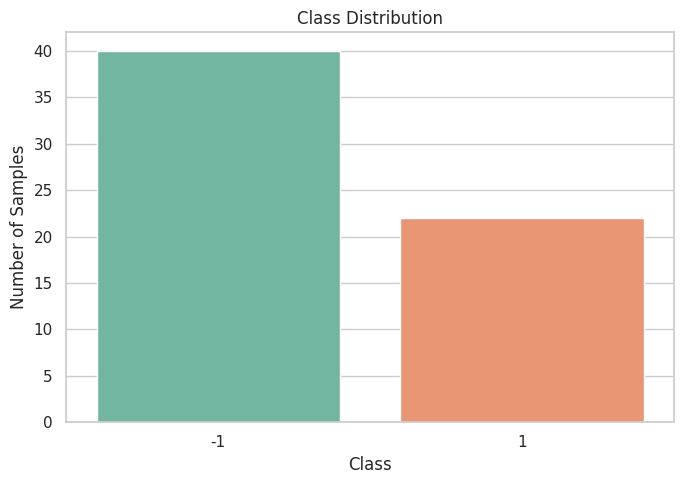

In [ ]:
plt.figure(figsize=(7, 5))

sns.countplot(
    x=y,
    hue=y,
    palette="Set2",
    legend=False
)

plt.title("Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Samples")

plt.tight_layout()
plt.show()

In [ ]:
missing_values = df.isnull().sum()

print("Total missing values:", missing_values.sum())

print("\nColumns with missing values:")
print(missing_values[missing_values > 0])

Total missing values: 0

Columns with missing values:
Series([], dtype: int64)


In [ ]:
print(df.dtypes.value_counts())

print("\nTarget data type:")
print(df["class"].dtype)

float64    2000
int64         1
Name: count, dtype: int64

Target data type:
int64


In [ ]:
constant_features = X.columns[
    X.nunique() <= 1
]

print("Number of constant features:", len(constant_features))

print("Constant feature names:")
print(list(constant_features))

Number of constant features: 0
Constant feature names:
[]


In [ ]:
duplicate_features = X.columns[
    X.T.duplicated()
]

print("Number of duplicate features:", len(duplicate_features))

print("Duplicate feature names:")
print(list(duplicate_features))

Number of duplicate features: 9
Duplicate feature names:
['att_40', 'att_41', 'att_42', 'att_51', 'att_52', 'att_53', 'att_261', 'att_262', 'att_263']


In [ ]:
display(X.describe().T)

,count,mean,std,min,25%,50%,75%,max
att_1,62.0,1.774194e-07,1.000000,-2.34557,-0.675473,0.131483,0.695364,2.08075
att_2,62.0,9.677419e-08,1.000000,-2.62049,-0.528863,0.138897,0.634424,1.69310
att_3,62.0,-1.451613e-07,1.000000,-2.76391,-0.654416,0.115090,0.692175,1.55925
att_4,62.0,8.064516e-08,1.000000,-2.18024,-0.585557,0.106972,0.656737,2.52569
att_5,62.0,4.838710e-08,1.000000,-2.12120,-0.524960,-0.135848,0.614213,2.89500
...,...,...,...,...,...,...,...,...
att_1996,62.0,-1.290323e-07,1.000000,-3.59586,-0.437383,0.077622,0.630752,2.06893
att_1997,62.0,-1.612903e-07,1.000000,-2.38787,-0.634321,0.164641,0.642602,1.85698
att_1998,62.0,-8.953411e-18,1.000000,-2.87057,-0.565987,0.007232,0.695627,1.84654
att_1999,62.0,1.612903e-07,0.999999,-2.86034,-0.674146,0.048154,0.719346,1.59153


In [ ]:
print("Mean of feature means:", X.mean().mean())

print("Mean of feature standard deviations:", X.std().mean())

print("Minimum value:", X.min().min())

print("Maximum value:", X.max().max())

Mean of feature means: 4.733870967092735e-09
Mean of feature standard deviations: 0.999999991418211
Minimum value: -5.24166
Maximum value: 4.50115


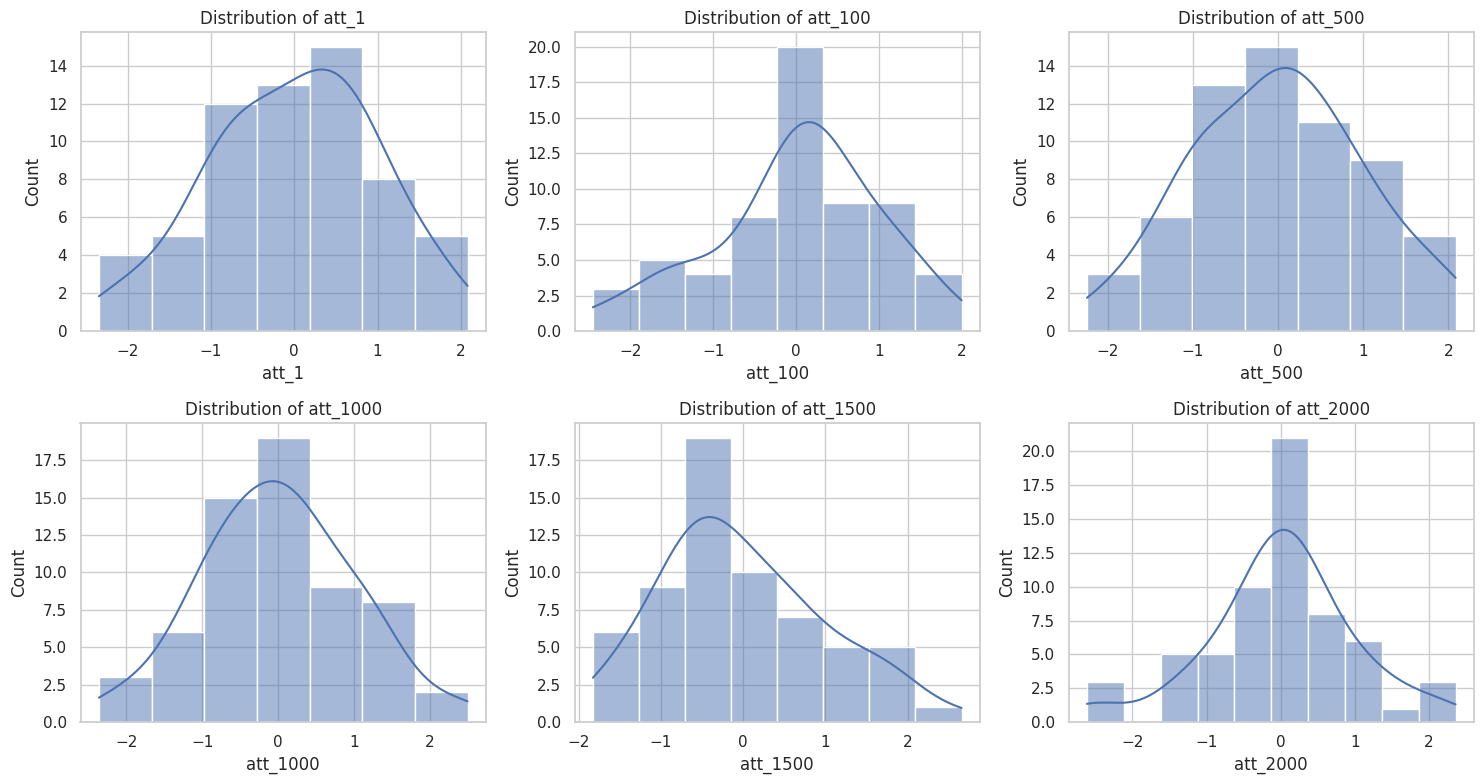

In [ ]:
selected_features = [
    "att_1",
    "att_100",
    "att_500",
    "att_1000",
    "att_1500",
    "att_2000"
]

fig, axes = plt.subplots(
    2, 3,
    figsize=(15, 8)
)

for ax, feature in zip(axes.flatten(), selected_features):

    sns.histplot(
        X[feature],
        kde=True,
        ax=ax
    )

    ax.set_title(f"Distribution of {feature}")

plt.tight_layout()
plt.show()

In [ ]:
OUTPUT_PATH = PROJECT_PATH / "datasets" / "colon_dataset.csv"

df.to_csv(
    OUTPUT_PATH,
    index=False
)

print("CSV file saved successfully!")
print("Saved at:", OUTPUT_PATH)

CSV file saved successfully!
Saved at: /content/drive/MyDrive/WOA_Project/datasets/colon_dataset.csv


In [ ]:
CSV_PATH = PROJECT_PATH / "datasets" / "colon_dataset.csv"

df.to_csv(CSV_PATH, index=False)

print("Dataset saved successfully!")
print("Saved path:", CSV_PATH)
print("Dataset shape:", df.shape)

Dataset saved successfully!
Saved path: /content/drive/MyDrive/WOA_Project/datasets/colon_dataset.csv
Dataset shape: (62, 2001)


In [ ]:
import pandas as pd

df_check = pd.read_csv(CSV_PATH)

print("Loaded shape:", df_check.shape)
print("Original shape:", df.shape)
print("File exists:", CSV_PATH.exists())

Loaded shape: (62, 2001)
Original shape: (62, 2001)
File exists: True
